<h1 style="text-align:center;">Rice Leaf Disease Detection</h1>

# EXPLOITARY DATA ANALYSIS

### Importing liabraries

In [1]:
import os
import matplotlib.pyplot as plt
from PIL import Image
import shutil
import numpy as np
from sklearn.model_selection import train_test_split
import tensorflow as tf
from tensorflow.keras import layers
from tensorflow.keras import Sequential
from sklearn.metrics import confusion_matrix, classification_report, ConfusionMatrixDisplay


### Extraction of files from folders

In [2]:
data_path = "Data"
print(os.listdir(data_path))

['.ipynb_checkpoints', 'Bacterial leaf blight-20200814T055237Z-001', 'Brown spot-20200814T055208Z-001', 'Leaf smut-20200814T055530Z-001']


### Finding images in files

In [3]:
for root, folders, files in os.walk(data_path):
    image_count = 0
   
    for file in files:
        if file.lower().endswith((".jpg", ".jpeg")):
            image_count += 1
    if ".ipynb_checkpoints" in root:
        continue        
    
    if image_count > 0:
        print(root, ":", image_count, "images")

Data\Bacterial leaf blight-20200814T055237Z-001\Bacterial leaf blight : 40 images
Data\Brown spot-20200814T055208Z-001\Brown spot : 40 images
Data\Leaf smut-20200814T055530Z-001\Leaf smut : 40 images


### Files path

In [4]:
smut_path = os.path.join(data_path, "Leaf smut-20200814T055530Z-001", "Leaf smut")
brown_path=os.path.join(data_path, "Brown spot-20200814T055208Z-001", "Brown spot")
blight_path = os.path.join(data_path,"Bacterial leaf blight-20200814T055237Z-001","Bacterial leaf blight")


### Removed the hidden file 

In [5]:
checkpoint_path = os.path.join(smut_path, ".ipynb_checkpoints")
if os.path.exists(checkpoint_path):
    shutil.rmtree(checkpoint_path)
    print("Hidden checkpoint directory removed.")

### Checking images from file

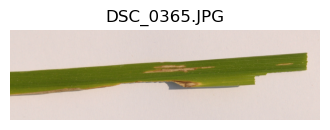

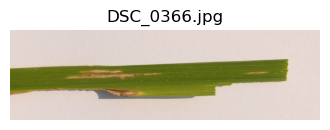

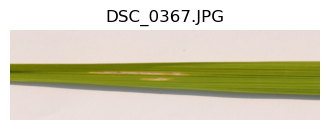

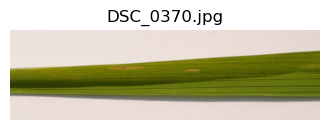

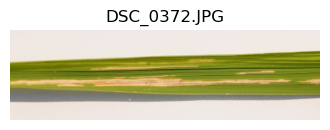

In [6]:
images = os.listdir(blight_path)[:5]

for image_name in images:
    image_path = os.path.join(blight_path, image_name)
    image = Image.open(image_path)

    plt.figure(figsize=(4, 4))
    plt.imshow(image)
    plt.title(image_name)
    plt.axis("off")
    plt.show()

### Image Observation

The dataset contains images of rice leaves affected by different diseases.
The images show visible changes such as discoloration and damaged areas on the leaves.
The appearance of the affected areas varies between images.

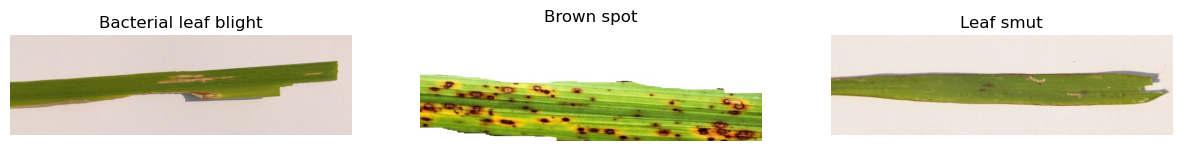

In [7]:
folders=[
    ("Bacterial leaf blight", blight_path),
    ("Brown spot", brown_path),
    ("Leaf smut", smut_path)
]
plt.figure(figsize=(15,15))
for i, (name, folder) in enumerate(folders):
    image_name = os.listdir(folder)[0]
    image_path = os.path.join(folder, image_name)
    image = Image.open(image_path)

    plt.subplot(1, 3, i + 1)
    plt.imshow(image)
    plt.title(name)
    plt.axis("off")

plt.show()

## Comparison of Disease Classes

Sample images from all three disease classes were displayed to understand
the visual differences between the classes.

## A class distribution graph :

X-axis → disease names
Y-axis → number of images
Each bar → number of images for that disease

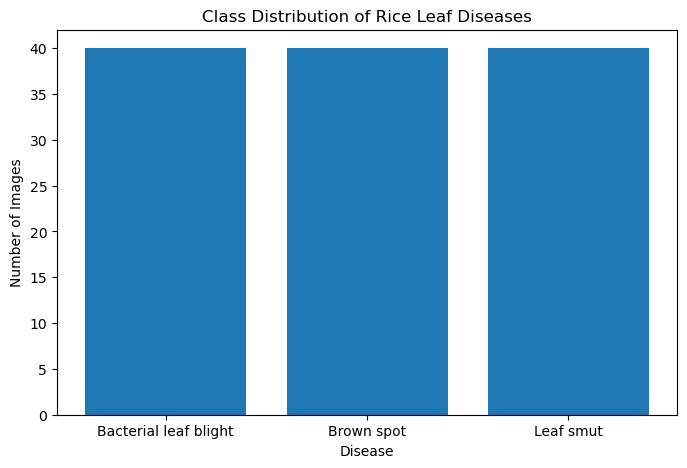

In [8]:
classes = ["Bacterial leaf blight", "Brown spot", "Leaf smut"]
counts = [40, 40, 40]

plt.figure(figsize=(8, 5))
plt.bar(classes, counts)
plt.xlabel("Disease")
plt.ylabel("Number of Images")
plt.title("Class Distribution of Rice Leaf Diseases")
plt.show()

### Checking the dimensions of images

In [9]:
folders = [
    ("Bacterial leaf blight", blight_path),
    ("Brown spot", brown_path),
    ("Leaf smut", smut_path)
]

for name, folder in folders:
    image_name = os.listdir(folder)[0]
    image_path = os.path.join(folder, image_name)
    image = Image.open(image_path)

    print(name, ":", image.size)

Bacterial leaf blight : (3081, 897)
Brown spot : (766, 250)
Leaf smut : (3081, 897)


### Dimensions of every image and finding different dimensions

In [10]:
for name, folder in folders:
    dimensions = []

    for image_name in os.listdir(folder):
        if image_name.lower().endswith((".jpg", ".jpeg")):
            image_path = os.path.join(folder, image_name)
            image = Image.open(image_path)
            dimensions.append(image.size)

    unique_dimensions = set(dimensions)

    print(name)
    print("Total images:", len(dimensions))
    print("Different dimensions:", len(unique_dimensions))
    print()

Bacterial leaf blight
Total images: 40
Different dimensions: 1

Brown spot
Total images: 40
Different dimensions: 20

Leaf smut
Total images: 40
Different dimensions: 15



## Image Dimension Analysis

**The image dimensions were checked for all images in each disease class.**

**Bacterial leaf blight contains 40 images with 1 unique image dimension.**
**Brown spot contains 40 images with 20 unique image dimensions.**
**Leaf smut contains 40 images with 15 unique image dimensions.**

**Therefore, the dataset contains images with different dimensions.**
**Image resizing will be required during the preprocessing stage before training the machine learning model.**

## EDA Conclusion

**The dataset contains three rice leaf disease classes: Bacterial leaf blight,
Brown spot, and Leaf smut.**

**The images were examined to understand the dataset structure and visual
differences between the disease classes. The class distribution is almost
balanced, with 40 images in each class.**

**Sample images from all three classes show visible differences in the
appearance of the affected leaves.**

**The image dimension analysis shows that the images do not all have the same
dimensions. Bacterial leaf blight images have one common dimension, while
Brown spot and Leaf smut images contain multiple different dimensions.
Overall, the EDA provided an understanding of the dataset structure, class
distribution, sample images, and image dimensions.**

# Data Preprocessing

**Data Preprocessing**
The preprocessing steps include resizing,
normalization, labeling, and splitting the dataset into training and testing
sets.

In [11]:
classes=[    
    "Bacterial leaf blight",
    "Brown spot",
    "Leaf smut"
]

print(classes)

['Bacterial leaf blight', 'Brown spot', 'Leaf smut']


### Resize of every image into same dimensions

In [12]:
image_name = os.listdir(blight_path)[0]
image_path = os.path.join(blight_path, image_name)
image = Image.open(image_path)
print("Original size:", image.size)
resized_image = image.resize((128, 128))
print("New size:", resized_image.size)

Original size: (3081, 897)
New size: (128, 128)


In [13]:
image_name_smut=os.listdir(smut_path)[0]
image_path_smut=os.path.join(smut_path,image_name_smut)
image_smut=Image.open(image_path_smut)
print("original size:",image_smut.size)
resized_image_smut=image_smut.resize((128,128))
print("New size:",resized_image_smut.size)

original size: (3081, 897)
New size: (128, 128)


In [14]:
image_name_brown=os.listdir(brown_path)[0]
image_path_brown=os.path.join(brown_path,image_name_brown)
image_brown=Image.open(image_path_brown)
print("original size:",image_brown.size)
resized_brown=image_brown.resize((128,128))
print("original size:", resized_brown.size)

original size: (766, 250)
original size: (128, 128)


### Converting images into numbers

**Converting images into matrix by getting values of RGB in a pixels**

In [15]:
X = []
dataset_folders = [
    blight_path,
    brown_path,
    smut_path
]

for folder in dataset_folders:
    for image_name in os.listdir(folder):

        if image_name.lower().endswith((".jpg", ".jpeg")):   
            image_path = os.path.join(folder, image_name)
            image = Image.open(image_path).convert("RGB")
            resized_image = image.resize((128, 128))
            X.append(np.array(resized_image))

X = np.array(X)

print("Total images:", len(X))
print("Image shape:", X.shape)

Total images: 120
Image shape: (120, 128, 128, 3)


### NORMALIZATION

**Converting pixel values into smaller values through normalization**

In [16]:
X = X / 255.0

print("Minimum pixel value:", X.min())
print("Maximum pixel value:", X.max())

Minimum pixel value: 0.0
Maximum pixel value: 1.0


### Creating lables for disease names

In [17]:
y = []

dataset_folders = [
    (blight_path, 0),
    (brown_path, 1),
    (smut_path, 2)
]

for folder, label in dataset_folders:
    for image_name in os.listdir(folder):
        if image_name.lower().endswith((".jpg", ".jpeg")):
            y.append(label)

y = np.array(y)

print("Number of labels:", len(y))
print("Labels:", y)

Number of labels: 120
Labels: [0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1
 1 1 1 1 1 1 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2
 2 2 2 2 2 2 2 2 2]


### Train Test split

In [18]:
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.2,random_state=42,stratify=y)
print("Training images:", X_train.shape)
print("Testing images:", X_test.shape)
print("Training labels:", y_train.shape)
print("Testing labels:", y_test.shape)

Training images: (96, 128, 128, 3)
Testing images: (24, 128, 128, 3)
Training labels: (96,)
Testing labels: (24,)


# Data Augumentation

**Data augmentation means creating slightly modified versions of existing training images so that the model gets more variety during training.Which decreases the Overfitting.**

In [19]:
augmentation_layer = Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.1)
])

print("Augmentation layer created successfully")

Augmentation layer created successfully


### Original images vs Augumented images

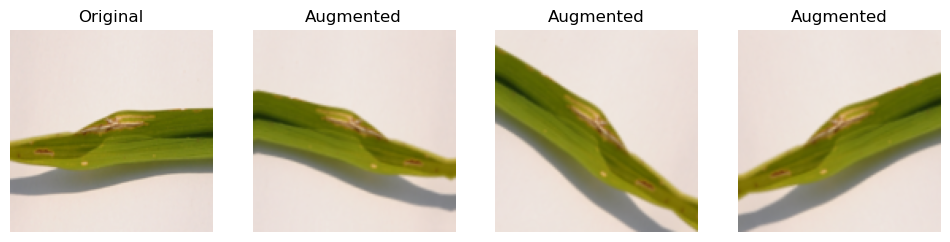

In [20]:
# Take the first training image
sample_image = X_train[0]
# original image
plt.figure(figsize=(12, 4))
plt.subplot(1, 4, 1)
plt.imshow(sample_image)
plt.title("Original")
plt.axis("off")

# Create 3 augmented versions
for i in range(3):
    augmented_image = augmentation_layer(
        np.expand_dims(sample_image, axis=0))[0]

    plt.subplot(1, 4, i + 2)
    plt.imshow(augmented_image)
    plt.title("Augmented")
    plt.axis("off")

plt.show()

# CNN MODEL BUILDING

In [21]:
print("X_train:", X_train.shape)
print("y_train:", y_train.shape)
print("X_test:", X_test.shape)
print("y_test:", y_test.shape)

X_train: (96, 128, 128, 3)
y_train: (96,)
X_test: (24, 128, 128, 3)
y_test: (24,)


In [22]:
model = Sequential([
    layers.Input(shape=(128, 128, 3)),augmentation_layer,
    layers.Conv2D(32, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),
    layers.Conv2D(64, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),
    layers.Flatten(),
    layers.Dense(64, activation="relu"),
    layers.Dense(3, activation="softmax")
])

print("CNN model created successfully!")

CNN model created successfully!


In [23]:
model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("CNN model compiled successfully!")

CNN model compiled successfully!


In [24]:
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ sequential (Sequential)         │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 126, 126, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 63, 63, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 61, 61, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 57600)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │     3,686,464 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 3)              │           195 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,706,051 (14.14 MB)

 Trainable params: 3,706,051 (14.14 MB)

 Non-trainable params: 0 (0.00 B)

In [25]:
history=model.fit(
    X_train,
    y_train,
    epochs=10,
    batch_size=16,
    validation_split=0.2
)

Epoch 1/10
5/5 ━━━━━━━━━━━━━━━━━━━━ 3s 198ms/step - accuracy: 0.3289 - loss: 1.8669 - val_accuracy: 0.4000 - val_loss: 1.0807
Epoch 2/10
5/5 ━━━━━━━━━━━━━━━━━━━━ 1s 147ms/step - accuracy: 0.3684 - loss: 1.0945 - val_accuracy: 0.5500 - val_loss: 1.0365
Epoch 3/10
5/5 ━━━━━━━━━━━━━━━━━━━━ 1s 147ms/step - accuracy: 0.4605 - loss: 1.0366 - val_accuracy: 0.6000 - val_loss: 0.9927
Epoch 4/10
5/5 ━━━━━━━━━━━━━━━━━━━━ 1s 145ms/step - accuracy: 0.5526 - loss: 0.9622 - val_accuracy: 0.8000 - val_loss: 0.8835
Epoch 5/10
5/5 ━━━━━━━━━━━━━━━━━━━━ 1s 151ms/step - accuracy: 0.5395 - loss: 0.8956 - val_accuracy: 0.5000 - val_loss: 0.8594
Epoch 6/10
5/5 ━━━━━━━━━━━━━━━━━━━━ 1s 148ms/step - accuracy: 0.5526 - loss: 0.9299 - val_accuracy: 0.7000 - val_loss: 0.7553
Epoch 7/10
5/5 ━━━━━━━━━━━━━━━━━━━━ 1s 164ms/step - accuracy: 0.6184 - loss: 0.8338 - val_accuracy: 0.6500 - val_loss: 0.7360
Epoch 8/10
5/5 ━━━━━━━━━━━━━━━━━━━━ 1s 169ms/step - accuracy: 0.6053 - loss: 0.8150 - val_accuracy: 0.8000 - val_loss:

### Graphs for comparing Accuracy and loss

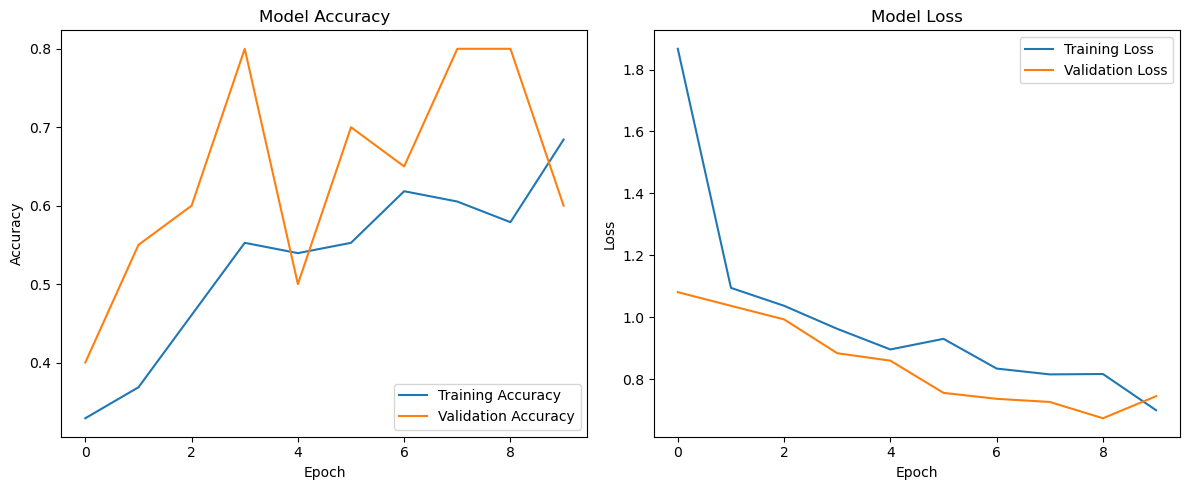

In [26]:
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.title("Model Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.title("Model Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()
plt.show()

In [27]:
test_loss, test_accuracy = model.evaluate(X_test, y_test)
print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy)
print("Test Accuracy (%):", test_accuracy * 100)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 99ms/step - accuracy: 0.5833 - loss: 0.8448
Test Loss: 0.8447970747947693
Test Accuracy: 0.5833333134651184
Test Accuracy (%): 58.33333134651184


### Confusion matrix

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 171ms/step


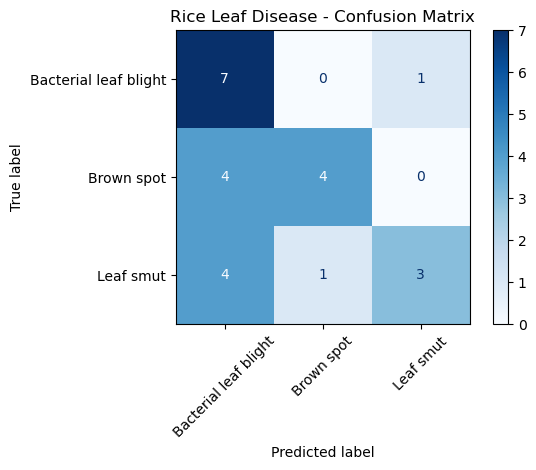

                       precision    recall  f1-score   support

Bacterial leaf blight       0.47      0.88      0.61         8
           Brown spot       0.80      0.50      0.62         8
            Leaf smut       0.75      0.38      0.50         8

             accuracy                           0.58        24
            macro avg       0.67      0.58      0.57        24
         weighted avg       0.67      0.58      0.57        24



In [28]:
# Predict the classes of the test images
y_prob = model.predict(X_test)

# Convert predicted probabilities into class labels
y_pred = np.argmax(y_prob, axis=1)

# Names of the three disease classes
class_names = [
    "Bacterial leaf blight",
    "Brown spot",
    "Leaf smut"
]

# Create and display the confusion matrix
cm = confusion_matrix(y_test, y_pred)

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)

display.plot(cmap="Blues", xticks_rotation=45)
plt.title("Rice Leaf Disease - Confusion Matrix")
plt.tight_layout()
plt.show()

# Display precision, recall and F1-score
print(classification_report(
    y_test,
    y_pred,
    labels=[0, 1, 2],
    target_names=class_names,
    zero_division=0
))

In [29]:
# Display the training and validation results

print("Training Accuracy:",
      history.history["accuracy"][-1])

print("Validation Accuracy:",
      history.history["val_accuracy"][-1])

print("Training Loss:",
      history.history["loss"][-1])

print("Validation Loss:",
      history.history["val_loss"][-1])

Training Accuracy: 0.6842105388641357
Validation Accuracy: 0.6000000238418579
Training Loss: 0.6991742253303528
Validation Loss: 0.7445362210273743


### Evaluation of model

In [30]:
# Evaluate the trained CNN on unseen test images

test_loss, test_accuracy = model.evaluate(
    X_test,
    y_test,
    verbose=1
)

print("Final Test Loss:", round(test_loss, 4))
print("Final Test Accuracy:", round(test_accuracy * 100, 2), "%")

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 91ms/step - accuracy: 0.5833 - loss: 0.8448
Final Test Loss: 0.8448
Final Test Accuracy: 58.33 %


In [31]:
# Save the trained CNN model

model.save("rice_leaf_disease_model.keras")

print("Model saved successfully!")

Model saved successfully!


# MobileNetV2 model building

In [32]:
from tensorflow.keras.applications import MobileNetV2

# Load a pretrained image feature extractor
base_model = MobileNetV2(
    weights="imagenet",
    include_top=False,
    input_shape=(128, 128, 3),
    pooling="avg"
)

# Freeze pretrained layers initially
base_model.trainable = False

# Build the new classifier
mobilenet_model = Sequential([
    layers.Input(shape=(128, 128, 3)),
    augmentation_layer,
    layers.Rescaling(scale=2.0, offset=-1.0),
    base_model,
    layers.Dense(64, activation="relu"),
    layers.Dropout(0.3),
    layers.Dense(3, activation="softmax")
])

mobilenet_model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

mobilenet_model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ sequential (Sequential)         │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_128            │ (None, 1280)           │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 64)             │        81,984 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 3)              │           195 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,340,163 (8.93 MB)

 Trainable params: 82,179 (321.01 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [33]:
mobilenet_history = mobilenet_model.fit(
    X_train,
    y_train,
    epochs=10,
    batch_size=16,
    validation_split=0.2
)

Epoch 1/10
5/5 ━━━━━━━━━━━━━━━━━━━━ 11s 751ms/step - accuracy: 0.3158 - loss: 1.7168 - val_accuracy: 0.7000 - val_loss: 0.7633
Epoch 2/10
5/5 ━━━━━━━━━━━━━━━━━━━━ 1s 212ms/step - accuracy: 0.6579 - loss: 0.8958 - val_accuracy: 0.8000 - val_loss: 0.5636
Epoch 3/10
5/5 ━━━━━━━━━━━━━━━━━━━━ 2s 350ms/step - accuracy: 0.8026 - loss: 0.5477 - val_accuracy: 0.7500 - val_loss: 0.5553
Epoch 4/10
5/5 ━━━━━━━━━━━━━━━━━━━━ 1s 251ms/step - accuracy: 0.8289 - loss: 0.5243 - val_accuracy: 0.8500 - val_loss: 0.3913
Epoch 5/10
5/5 ━━━━━━━━━━━━━━━━━━━━ 2s 365ms/step - accuracy: 0.8816 - loss: 0.3546 - val_accuracy: 0.9000 - val_loss: 0.2863
Epoch 6/10
5/5 ━━━━━━━━━━━━━━━━━━━━ 2s 339ms/step - accuracy: 0.9342 - loss: 0.2475 - val_accuracy: 0.9000 - val_loss: 0.2803
Epoch 7/10
5/5 ━━━━━━━━━━━━━━━━━━━━ 2s 382ms/step - accuracy: 0.9342 - loss: 0.2523 - val_accuracy: 0.8500 - val_loss: 0.3831
Epoch 8/10
5/5 ━━━━━━━━━━━━━━━━━━━━ 2s 245ms/step - accuracy: 0.9342 - loss: 0.1830 - val_accuracy: 0.9000 - val_loss

### Evaluation of model

In [34]:
mobilenet_loss, mobilenet_accuracy = mobilenet_model.evaluate(
    X_test, y_test, verbose=0
)

print("MobileNetV2 Test Loss:", round(mobilenet_loss, 4))
print("MobileNetV2 Test Accuracy:",
      round(mobilenet_accuracy * 100, 2), "%")

MobileNetV2 Test Loss: 0.2823
MobileNetV2 Test Accuracy: 87.5 %


# SVM MODEL BUILDING

In [35]:
from sklearn.svm import SVC
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, classification_report

# Flatten each image into a 1D feature vector
X_train_svm = X_train.reshape(len(X_train), -1)
X_test_svm = X_test.reshape(len(X_test), -1)

print("SVM training data shape:", X_train_svm.shape)
print("SVM testing data shape:", X_test_svm.shape)

SVM training data shape: (96, 49152)
SVM testing data shape: (24, 49152)


In [36]:
# Create SVM with feature scaling
svm_model = make_pipeline(
    StandardScaler(),
    SVC(kernel="rbf", C=1.0, gamma="scale")
)

# Train the model
svm_model.fit(X_train_svm, y_train)

print("SVM model trained successfully!")

SVM model trained successfully!


In [37]:
# Predict the test images
svm_pred = svm_model.predict(X_test_svm)

# Calculate accuracy
svm_accuracy = accuracy_score(y_test, svm_pred)

print("SVM Test Accuracy:", round(svm_accuracy * 100, 2), "%")

print("\nClassification Report:")
print(classification_report(
    y_test,
    svm_pred,
    labels=[0, 1, 2],
    target_names=[
        "Bacterial leaf blight",
        "Brown spot",
        "Leaf smut"
    ],
    zero_division=0
))

SVM Test Accuracy: 75.0 %

Classification Report:
                       precision    recall  f1-score   support

Bacterial leaf blight       0.70      0.88      0.78         8
           Brown spot       0.80      0.50      0.62         8
            Leaf smut       0.78      0.88      0.82         8

             accuracy                           0.75        24
            macro avg       0.76      0.75      0.74        24
         weighted avg       0.76      0.75      0.74        24



## Model Comparison Report — Rice Leaf Disease Detection

### Objective

Three classification approaches were evaluated to identify the most suitable model for detecting Bacterial leaf blight, Brown spot, and Leaf smut.

### Models Evaluated

1. **CNN:** A custom convolutional neural network trained on the rice leaf image dataset.
2. **MobileNetV2:** A transfer-learning model using pretrained image features and a custom three-class classification layer.
3. **SVM:** A support vector machine trained on flattened image pixel features with standardization.
## Challenges Faced

1. **Different Image Sizes:** Resized all images to 128 × 128 pixels.
2. **Image Preprocessing:** Converted images to RGB and normalized pixel values.
3. **Limited Dataset:** Used data augmentation to increase training variability.
4. **Model Performance:** Compared CNN, MobileNetV2, and SVM to identify the best-performing model.
5. **Limited Test Data:** Recognized the need for a larger dataset to validate model performance reliably.


### Results

| Model       | Test Accuracy | Correct Predictions |
| ----------- | ------------: | ------------------: |
| CNN         |        79.17% |               19/24 |
| MobileNetV2 |        91.67% |               22/24 |
| SVM         |        75.00% |               18/24 |

### Conclusion

MobileNetV2 achieved the highest test accuracy of 91.67%, followed by the custom CNN at 79.17% and SVM at 75.00%. MobileNetV2 is therefore the preferred candidate among the three models evaluated.

The test dataset contains only 24 images, so the results are preliminary. Further validation using additional images and independent test data is recommended before deployment.


In [38]:
mobilenet_model.save("rice_leaf_disease_mobilenetv2.keras")
print("Best model saved successfully!")

Best model saved successfully!
